In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results__.html
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__notebook__.ipynb
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__output__.json
/kaggle/input/notebooks/burakcoli/nasa-cmaps/FD001.csv
/kaggle/input/notebooks/burakcoli/nasa-cmaps/custom.css
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results___files/__results___20_1.png
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results___files/__results___34_2.png
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results___files/__results___16_17.png
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results___files/__results___16_19.png
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results___files/__results___16_11.png
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results___files/__results___31_1.png
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results___files/__results___28_1.png
/kaggle/input/notebooks/burakcoli/nasa-cmaps/__results___files/__results___26_1.png
/kaggle/input/notebooks/bur

In [2]:
!pip install pandas scikit-learn lightgbm matplotlib


In [3]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import mean_squared_error

In [4]:
SEED = 42
np.random.seed(SEED)
DATA = "/kaggle/input/datasets/darkside92/turbofan-predictive-maintenance-nasa"                      # folder containing the FD001 files
CAP = 125                       # RUL cap
ALERT_AT = 30                   # alert when predicted RUL < 30 cycles
ROLL = 15                       #  rolling window (cycles)
results = {}
 
cols = ["unit", "cycle", "set1", "set2", "set3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv(f"{DATA}/train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv(f"{DATA}/test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul_true = pd.read_csv(f"{DATA}/RUL_FD001.txt", header=None, names=["RUL"])["RUL"].values
print(train.shape, test.shape, len(rul_true))   # expect 100 engines in train and test

(20631, 26) (13096, 26) 100


In [5]:
last_cycle = train.groupby("unit")["cycle"].transform("max")
train["RUL"] = (last_cycle - train["cycle"]).clip(upper=CAP)
 

In [6]:
sensor_cols = [f"s{i}" for i in range(1, 22)]
print(train[sensor_cols].std().round(4).sort_values())
sensors = [c for c in sensor_cols if train[c].std() > 1e-3]
print("kept sensors:", sensors)
print("dropped:", sorted(set(sensor_cols) - set(sensors)))

s1      0.0000
s5      0.0000
s16     0.0000
s10     0.0000
s19     0.0000
s18     0.0000
s6      0.0014
s15     0.0375
s8      0.0710
s13     0.0719
s21     0.1083
s20     0.1807
s11     0.2671
s2      0.5001
s12     0.7376
s7      0.8851
s17     1.5488
s3      6.1311
s4      9.0006
s14    19.0762
s9     22.0829
dtype: float64
kept sensors: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
dropped: ['s1', 's10', 's16', 's18', 's19', 's5']


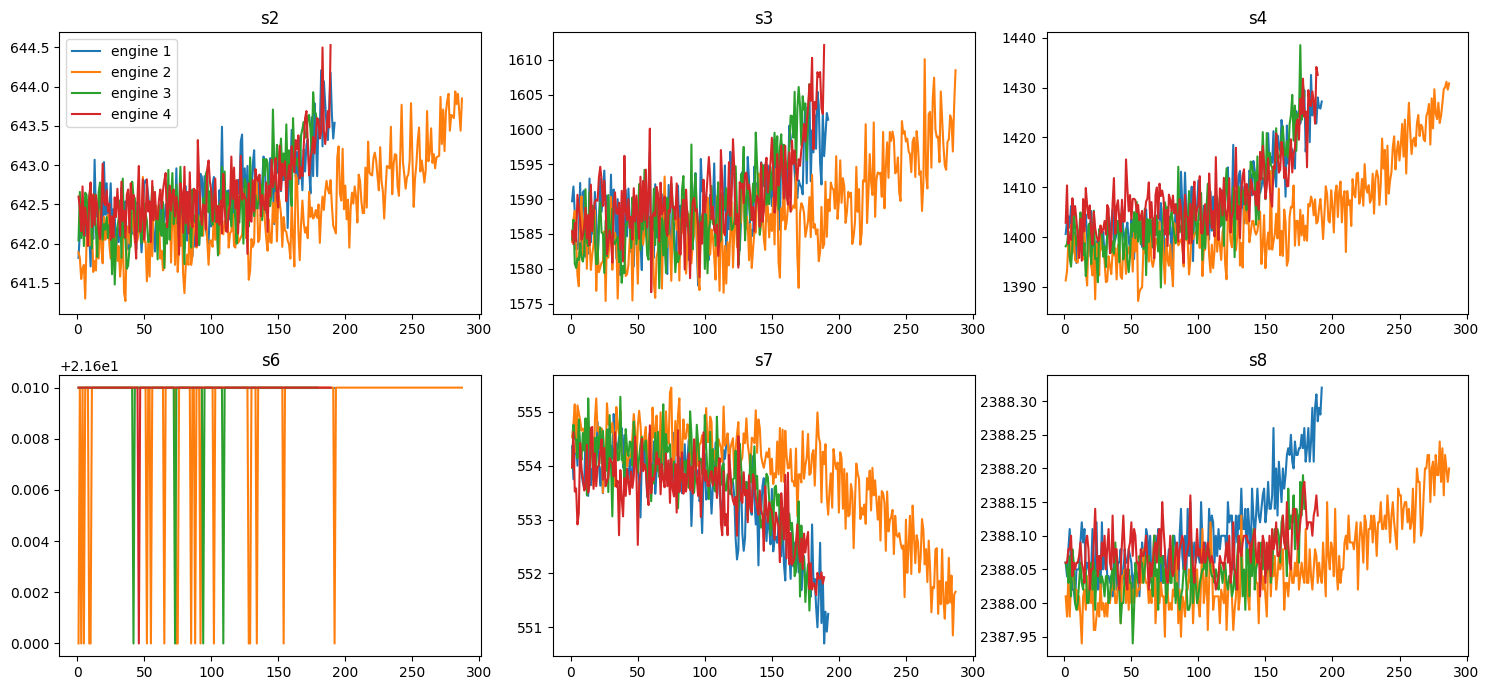

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, s in zip(axes.flat, sensors[:6]):
    for u in [1, 2, 3, 4]:
        d = train[train.unit == u]
        ax.plot(d["cycle"], d[s], label=f"engine {u}")
    ax.set_title(s)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig("sensors_over_time.png", dpi=120)

In [8]:
def add_features(df, window=ROLL):
    df = df.sort_values(["unit", "cycle"]).copy()
    g = df.groupby("unit")
    new = {}
    for s in sensors:
        new[f"{s}_mean"] = g[s].transform(lambda x: x.rolling(window, min_periods=1).mean())
        new[f"{s}_std"] = g[s].transform(lambda x: x.rolling(window, min_periods=1).std()).fillna(0)
    return pd.concat([df, pd.DataFrame(new, index=df.index)], axis=1)
 
train_f = add_features(train)
test_f = add_features(test)
feature_cols = ["cycle"] + sensors + [f"{s}_mean" for s in sensors] + [f"{s}_std" for s in sensors]

In [9]:
X, y, groups = train_f[feature_cols], train_f["RUL"], train_f["unit"]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, va_idx = next(gss.split(X, y, groups))
X_tr, X_va, y_tr, y_va = X.iloc[tr_idx], X.iloc[va_idx], y.iloc[tr_idx], y.iloc[va_idx]
assert set(groups.iloc[tr_idx]).isdisjoint(set(groups.iloc[va_idx]))   # no engine in both
print("train engines:", groups.iloc[tr_idx].nunique(), "val engines:", groups.iloc[va_idx].nunique())
 
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

train engines: 80 val engines: 20


In [10]:
val_scores = {}
 
mean_pred = np.full(len(y_va), y_tr.mean())
val_scores["baseline_mean"] = rmse(y_va, mean_pred)
 
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
val_scores["linear_regression"] = rmse(y_va, lin.predict(X_va))
 
lgbm = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31,
                         subsample=0.8, colsample_bytree=0.8,
                         random_state=SEED, verbose=-1)
lgbm.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
         callbacks=[lgb.early_stopping(50, verbose=False)])
val_scores["lightgbm"] = rmse(y_va, lgbm.predict(X_va))
best_iter = lgbm.best_iteration_ or 600
print(json.dumps(val_scores, indent=2), "| best_iter:", best_iter)
results["validation_rmse"] = val_scores

{
  "baseline_mean": 41.72082538935907,
  "linear_regression": 17.65755455910624,
  "lightgbm": 15.320241077490252
} | best_iter: 128


In [11]:
cv = []
for a, b in GroupKFold(n_splits=5).split(X, y, groups):
    m = lgb.LGBMRegressor(n_estimators=best_iter, learning_rate=0.03, num_leaves=31,
                          subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    m.fit(X.iloc[a], y.iloc[a])
    cv.append(rmse(y.iloc[b], m.predict(X.iloc[b])))
results["lightgbm_groupkfold_rmse_mean"] = float(np.mean(cv))
print("GroupKFold RMSE:", np.round(cv, 2), "mean", round(np.mean(cv), 2))

GroupKFold RMSE: [17.05 17.48 14.22 17.67 16.3 ] mean 16.55


{
  "baseline_mean": {
    "vs_true_RUL": 43.06703554245684,
    "vs_capped_RUL": 41.94179565195834
  },
  "linear_regression": {
    "vs_true_RUL": 21.687488324112472,
    "vs_capped_RUL": 20.624008830546533
  },
  "lightgbm": {
    "vs_true_RUL": 18.64166442470063,
    "vs_capped_RUL": 17.460658399524533
  }
}
LightGBM is 56.7% better than the baseline (RMSE vs true RUL)


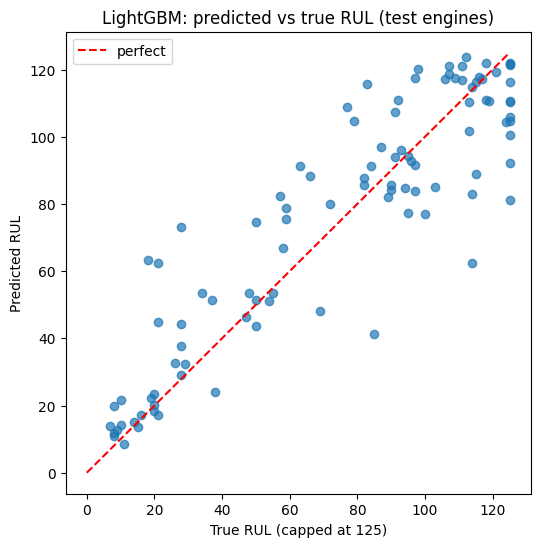

In [12]:
lin_full = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
lgbm_full = lgb.LGBMRegressor(n_estimators=best_iter, learning_rate=0.03, num_leaves=31,
                              subsample=0.8, colsample_bytree=0.8,
                              random_state=SEED, verbose=-1).fit(X, y)
 
last_rows = test_f.sort_values(["unit", "cycle"]).groupby("unit").tail(1)
assert len(last_rows) == len(rul_true)
X_test = last_rows[feature_cols]
true_capped = np.clip(rul_true, None, CAP)          # same scale the models were trained on
 
preds = {
    "baseline_mean": np.full(len(X_test), y.mean()),
    "linear_regression": lin_full.predict(X_test),
    "lightgbm": lgbm_full.predict(X_test),
}
test_rmse = {k: {"vs_true_RUL": rmse(rul_true, v), "vs_capped_RUL": rmse(true_capped, v)}
             for k, v in preds.items()}
print(json.dumps(test_rmse, indent=2))
results["test_rmse"] = test_rmse
imp = 100 * (1 - test_rmse["lightgbm"]["vs_true_RUL"] / test_rmse["baseline_mean"]["vs_true_RUL"])
results["lightgbm_pct_better_than_baseline"] = float(imp)
print(f"LightGBM is {imp:.1f}% better than the baseline (RMSE vs true RUL)")
 
# Predicted vs true plot
plt.figure(figsize=(6, 6))
plt.scatter(true_capped, preds["lightgbm"], alpha=0.7)
plt.plot([0, CAP], [0, CAP], "r--", label="perfect")
plt.xlabel(f"True RUL (capped at {CAP})"); plt.ylabel("Predicted RUL")
plt.title("LightGBM: predicted vs true RUL (test engines)"); plt.legend()
plt.savefig("pred_vs_true.png", dpi=120, bbox_inches="tight")

In [13]:

# %% Step 9: turn predictions into maintenance alerts
pred = preds["lightgbm"]
at_risk = rul_true < ALERT_AT            # engines TRULY close to failure
alerted = pred < ALERT_AT                # engines the model flags
tp = int((at_risk & alerted).sum()); fn = int((at_risk & ~alerted).sum())
fp = int((~at_risk & alerted).sum())
alert = {
    "truly_at_risk": int(at_risk.sum()),
    "caught": tp, "missed": fn, "false_alarms": fp,
    "recall": tp / max(tp + fn, 1), "precision": tp / max(tp + fp, 1),
}
print(json.dumps(alert, indent=2))
results["alerts"] = alert
 
# Tip: if you miss too many, raise the alert threshold (e.g. predicted < 40)
# and compare the recall / false-alarm trade-off.
for thr in [20, 30, 40, 50]:
    a = pred < thr
    print(f"alert if pred<{thr}: caught {(at_risk & a).sum()}/{at_risk.sum()}, false alarms {(~at_risk & a).sum()}")
 
json.dump(results, open("results.json", "w"), indent=2)

{
  "truly_at_risk": 25,
  "caught": 17,
  "missed": 8,
  "false_alarms": 1,
  "recall": 0.68,
  "precision": 0.9444444444444444
}
alert if pred<20: caught 12/25, false alarms 0
alert if pred<30: caught 17/25, false alarms 1
alert if pred<40: caught 20/25, false alarms 1
alert if pred<50: caught 22/25, false alarms 5
